# Homework 6 - Unsupervised Learning: K-Means and PCA on Pulsar Candidates

Author: Vadim Egorov

**Objective:** explore a real dataset with two unsupervised methods, K-Means clustering and Principal Component Analysis (PCA), and check whether the groups they find mean something.

**Dataset:** [HTRU2](https://archive.ics.uci.edu/dataset/372/htru2) (UCI Machine Learning Repository).

### The problem
A **pulsar** is a rapidly spinning neutron star. It sends out a beam of radio waves that sweeps past Earth once per rotation, so a radio telescope sees a regular train of pulses.

Pulsar surveys produce millions of **candidates** (repeating signals worth a closer look). Almost all of them are radio interference or noise, not real pulsars. Checking every candidate by hand is impossible, so we need automatic ways to sort them.

HTRU2 has **17,898 candidates** from the High Time Resolution Universe survey. Each candidate is described by **8 numbers**: the mean, standard deviation, skewness and kurtosis of two curves:

- **Integrated profile** (`Profile_*`): the signal folded over one rotation period, averaged into a single pulse shape. A real pulsar gives a sharp, narrow peak.
- **DM-SNR curve** (`DM_*`): signal-to-noise ratio as a function of *dispersion measure*, the frequency-dependent delay caused by gas between us and the source. A real pulsar peaks at one non-zero DM, while terrestrial interference peaks at DM ≈ 0.

**Questions:**
1. Without using any labels, do the candidates form natural groups?
2. What makes the groups different?
3. Does PCA give a useful 2D picture of those groups?

The dataset also has a `class` label (1 = pulsar, 0 = not). It is **not used** to fit anything. It's kept aside and used only at the end, to check whether the clusters line up with something real.

## 1. Imports + Setup

In [1]:
# ucimlrepo isn't preinstalled in Google Colab
%pip install -q ucimlrepo

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA

# Larger default size for all plots
plt.rcParams['figure.figsize'] = (11, 6)
plt.rcParams['font.size'] = 12

## 2. Load Data

In [3]:
# Fetch dataset
htru2 = fetch_ucirepo(id=372)

# Data as pandas dataframes
X = htru2.data.features
y = htru2.data.targets['class']

df = X.copy()
df['class'] = y

df

,Profile_mean,Profile_stdev,Profile_skewness,Profile_kurtosis,DM_mean,DM_stdev,DM_skewness,DM_kurtosis,class
0,140.562500,55.683782,-0.234571,-0.699648,3.199833,19.110426,7.975532,74.242225,0
1,102.507812,58.882430,0.465318,-0.515088,1.677258,14.860146,10.576487,127.393580,0
2,103.015625,39.341649,0.323328,1.051164,3.121237,21.744669,7.735822,63.171909,0
3,136.750000,57.178449,-0.068415,-0.636238,3.642977,20.959280,6.896499,53.593661,0
4,88.726562,40.672225,0.600866,1.123492,1.178930,11.468720,14.269573,252.567306,0
...,...,...,...,...,...,...,...,...,...
17893,136.429688,59.847421,-0.187846,-0.738123,1.296823,12.166062,15.450260,285.931022,0
17894,122.554688,49.485605,0.127978,0.323061,16.409699,44.626893,2.945244,8.297092,0
17895,119.335938,59.935939,0.159363,-0.743025,21.430602,58.872000,2.499517,4.595173,0
17896,114.507812,53.902400,0.201161,-0.024789,1.946488,13.381731,10.007967,134.238910,0


## 3. EDA - Exploratory Data Analysis

In [5]:
display(df.shape)
display(df.dtypes.value_counts())

(17898, 9)

float64    8
int64      1
Name: count, dtype: int64

### 3.1 Missing values and duplicates

In [6]:
missing_values_num = df.isnull().sum().sum()
duplicate_rows_num = df.duplicated().sum()

print(f"Number of missing values: {missing_values_num}")
print(f"Number of duplicate rows: {duplicate_rows_num}")

Number of missing values: 0
Number of duplicate rows: 0


### 3.2 The label we are *not* using
Only used for checking the clusters later.

In [7]:
class_counts = df['class'].value_counts()
print(class_counts)
print(f"Share of pulsars: {class_counts[1] / len(df):.1%}")

class
0    16259
1     1639
Name: count, dtype: int64
Share of pulsars: 9.2%


- Only **9.2%** of candidates (1,639) are real pulsars; the other 16,259 are noise or interference.
- So if K-Means finds a "pulsar" group, it should be small.

### 3.3 Feature distributions and scales

In [8]:
X.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Profile_mean,17898.0,111.08,25.65,5.81,100.93,115.08,127.09,192.62
Profile_stdev,17898.0,46.55,6.84,24.77,42.38,46.95,51.02,98.78
Profile_skewness,17898.0,0.48,1.06,-1.88,0.03,0.22,0.47,8.07
Profile_kurtosis,17898.0,1.77,6.17,-1.79,-0.19,0.20,0.93,68.10
DM_mean,17898.0,12.61,29.47,0.21,1.92,2.80,5.46,223.39
DM_stdev,17898.0,26.33,19.47,7.37,14.44,18.46,28.43,110.64
DM_skewness,17898.0,8.30,4.51,-3.14,5.78,8.43,10.70,34.54
DM_kurtosis,17898.0,104.86,106.51,-1.98,34.96,83.06,139.31,1191.00


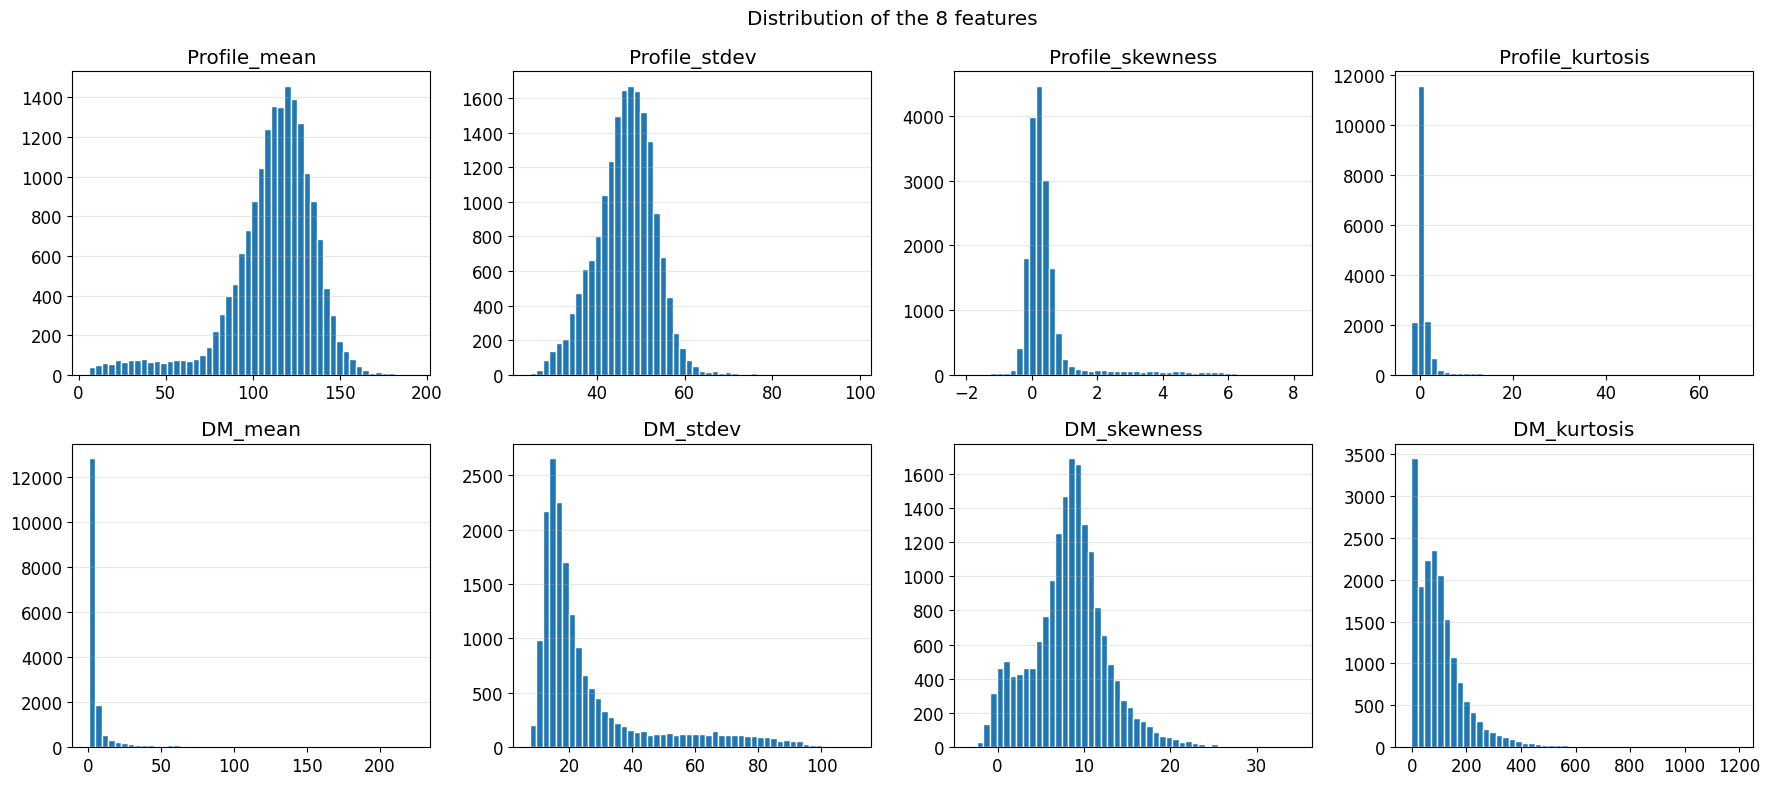

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))

for ax, col in zip(axes.flatten(), X.columns):
    ax.hist(X[col], bins=50, edgecolor='white')
    ax.set_title(col)
    ax.grid(axis='y', alpha=0.3)

plt.suptitle("Distribution of the 8 features")
plt.tight_layout()
plt.show()

In [10]:
X.skew().round(2)

Profile_mean       -1.38
Profile_stdev       0.13
Profile_skewness    3.64
Profile_kurtosis    5.18
DM_mean             3.68
DM_stdev            1.89
DM_skewness         0.44
DM_kurtosis         2.73
dtype: float64

- **The scales differ hugely:** std goes from about 1 (`Profile_skewness`) to about 107 (`DM_kurtosis`), so scaling is required (Section 4).
- **Most features are strongly right-skewed** (`Profile_kurtosis` 5.2, `DM_mean` 3.7, `Profile_skewness` 3.6): a large bulk of ordinary candidates plus a long tail of unusual ones.
- Standard scaling fixes the units but not this shape. The long tails will still pull on the K-Means centroids.

### 3.4 Correlation between features

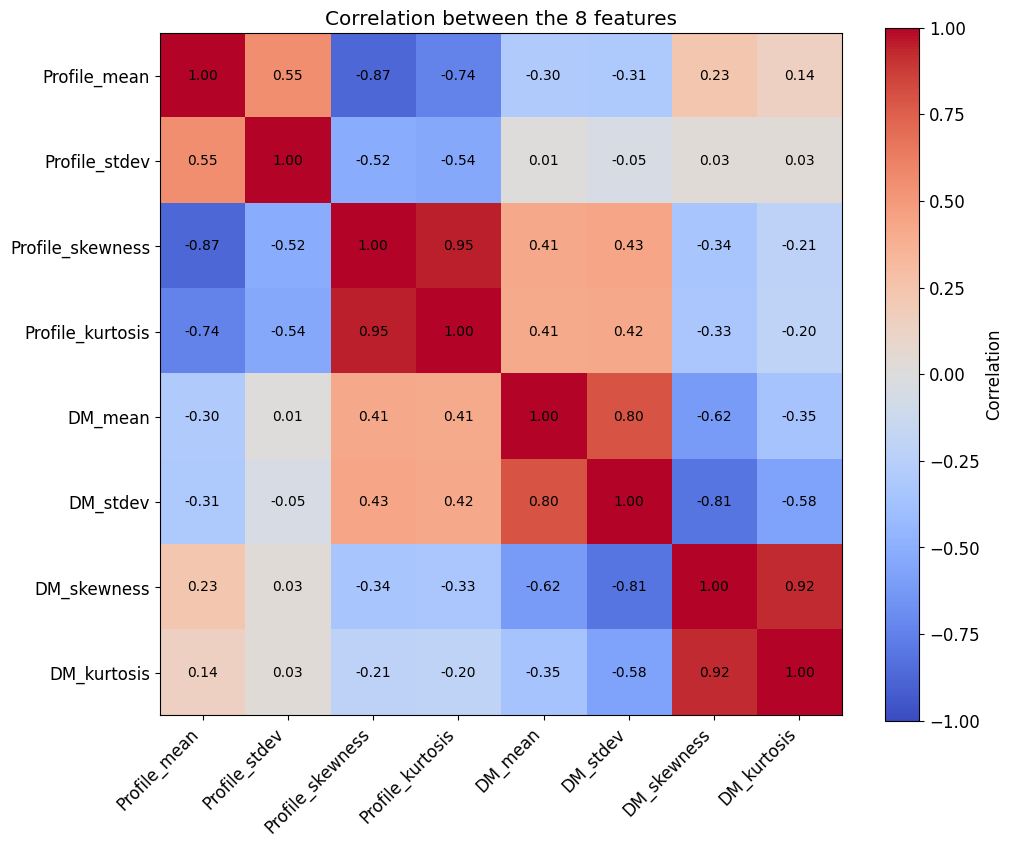

In [11]:
feature_corr = X.corr()

plt.figure(figsize=(11, 9))
plt.imshow(feature_corr, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(X.columns)), X.columns, rotation=45, ha='right')
plt.yticks(range(len(X.columns)), X.columns)

# Write the correlation value inside each square
for i in range(len(X.columns)):
    for j in range(len(X.columns)):
        plt.text(j, i, f"{feature_corr.iloc[i, j]:.2f}", ha='center', va='center', fontsize=10)

plt.title("Correlation between the 8 features")
plt.show()

- **Skewness and kurtosis move together** within each curve: r = 0.95 for the profile and 0.92 for the DM curve. They describe the same thing (how peaked the curve is).
- `DM_mean` and `DM_stdev` are also strongly linked (0.80).
- `Profile_mean` is strongly anti-correlated with `Profile_skewness` (−0.87): a narrow, sharp pulse means most of the profile is low baseline, so the mean drops.
- Strong correlations mean the 8 features hold fewer than 8 independent directions of information. **PCA should be able to compress them well.**

### 3.5 A first look in 2D

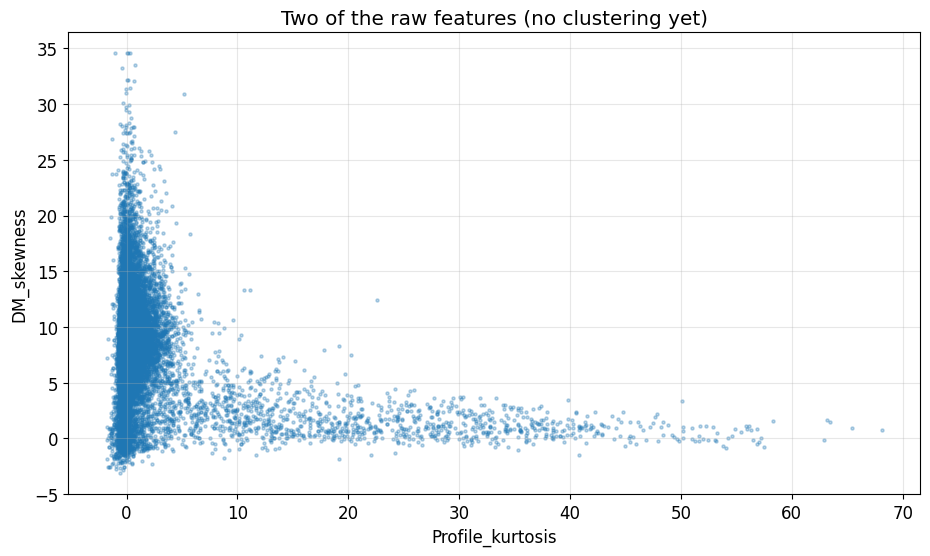

In [12]:
plt.scatter(X['Profile_kurtosis'], X['DM_skewness'], s=5, alpha=0.3)
plt.xlabel("Profile_kurtosis")
plt.ylabel("DM_skewness")
plt.title("Two of the raw features (no clustering yet)")
plt.grid(alpha=0.3)
plt.show()

## 4. Preprocessing

### 4.1 Scaling
K-Means and PCA are both based on distances and variances. Without scaling, `DM_kurtosis` (std ≈ 107) would outweigh `Profile_skewness` (std ≈ 1) simply because of its units. `StandardScaler` gives every feature **mean 0 and standard deviation 1**:

$$z = \frac{x - \mu}{\sigma}$$

There's no train/test split. Nothing is being predicted, so the scaler is fit on all the data.

In [13]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pd.DataFrame(X_scaled, columns=X.columns).describe().T[['mean', 'std']].round(3)

,mean,std
Profile_mean,-0.0,1.0
Profile_stdev,0.0,1.0
Profile_skewness,0.0,1.0
Profile_kurtosis,0.0,1.0
DM_mean,0.0,1.0
DM_stdev,0.0,1.0
DM_skewness,0.0,1.0
DM_kurtosis,0.0,1.0


Every feature now has mean 0 and std 1, so each one counts equally in the distance calculations.

## 5. K-Means Clustering

### 5.1 How K-Means works
K-Means splits the data into **K groups** so that each point is close to the center (**centroid**) of its own group:

1. Choose K and place K starting centroids.
2. **Assign** each point to its nearest centroid (Euclidean distance).
3. **Update** each centroid to the mean of the points assigned to it.
4. Repeat steps 2-3 until the assignments stop changing.

The algorithm minimizes the **within-cluster sum of squares (WCSS, also called inertia)**:

$$\text{WCSS} = \sum_{k=1}^{K} \sum_{x_i \in C_k} \lVert x_i - \mu_k \rVert^2$$

The result depends on the starting centroids, so `n_init=10` runs it 10 times and keeps the run with the lowest WCSS. `random_state=42` makes the results reproducible.

K-Means **can't choose K on its own**: WCSS always goes down as K grows. The Elbow Method and the Silhouette Score below are used to pick it.

### 5.2 Elbow Method
Plot WCSS for K = 1 to 8 and look for the "elbow", the point where adding another cluster stops reducing WCSS by much.

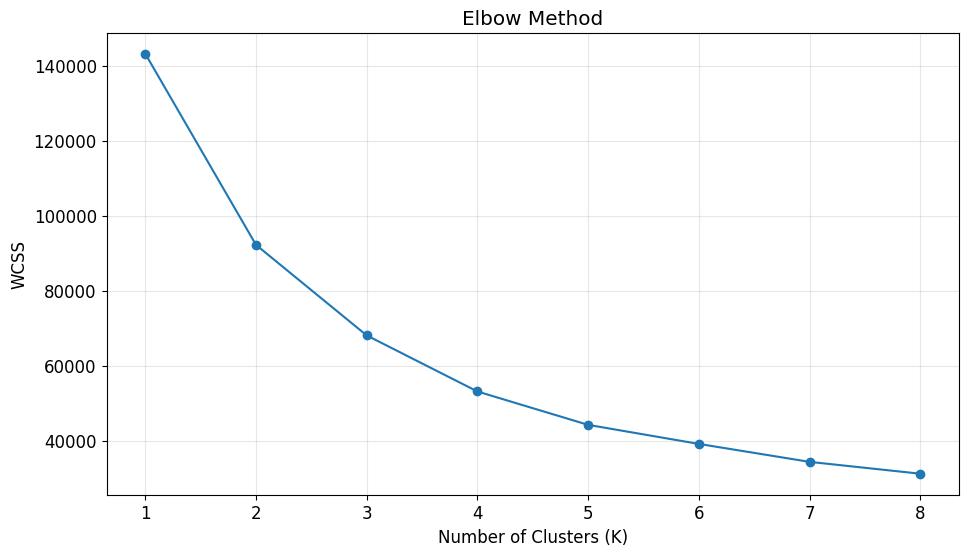

In [14]:
wcss = []

for k in range(1, 9):
    model = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=42
    )

    model.fit(X_scaled)
    wcss.append(model.inertia_)

plt.plot(range(1, 9), wcss, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.grid(alpha=0.3)
plt.show()

In [15]:
# How much WCSS drops with each extra cluster
elbow_table = pd.DataFrame({'K': range(1, 9), 'WCSS': np.round(wcss)})
elbow_table['Drop from previous K (%)'] = (-elbow_table['WCSS'].pct_change() * 100).round(1)
elbow_table

,K,WCSS,Drop from previous K (%)
0,1,143184.0,NaN
1,2,92214.0,35.6
2,3,68072.0,26.2
3,4,53122.0,22.0
4,5,44219.0,16.8
5,6,39139.0,11.5
6,7,34353.0,12.2
7,8,31191.0,9.2


- WCSS always goes down as K grows, so what matters is **how much** it drops: 35.6% (K=2), 26.2% (K=3), 22.0% (K=4), and then under 17% from K=5 onward.
- The curve bends **gradually around K = 3-4**; there's no sharp elbow. So the Elbow Method suggests a range, not one exact K.

### 5.3 Silhouette Score
For each point *i*:
- $a(i)$ = average distance to the other points in **its own** cluster (how tight the cluster is)
- $b(i)$ = average distance to the points in the **nearest other** cluster (how well separated it is)

$$s(i) = \frac{b(i) - a(i)}{\max\big(a(i),\, b(i)\big)}$$

The score ranges from −1 to 1. Close to 1 means the point is well inside its own cluster; close to 0 means it sits on a boundary. The Silhouette Score is the average of $s(i)$ over all points; **higher is better**. It needs at least 2 clusters, so K runs from 2 to 8.

*Takes about 30 seconds in Colab: the silhouette compares every pair of the 17,898 points.*

In [16]:
silhouette_scores = []

for k in range(2, 9):
    model = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = model.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

    print(k, round(score, 3))

2 0.601


3 0.518


4 0.36


5 0.303


6 0.271


7 0.273


8 0.278


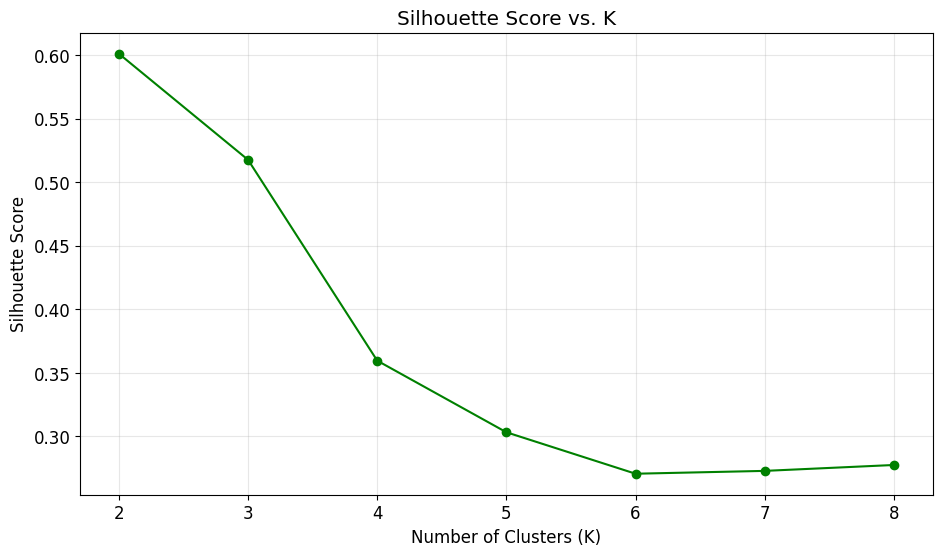

In [17]:
plt.plot(range(2, 9), silhouette_scores, marker="o", color='green')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score vs. K")
plt.grid(alpha=0.3)
plt.show()

- **K = 2 has the highest score (0.601)**, closely followed by **K = 3 (0.518)**.
- After that the score **drops sharply to 0.360 at K = 4** and levels off around 0.27-0.30 for K = 5-8. More clusters just cut the main cloud into arbitrary pieces with no clear gaps between them.

### 5.4 Choosing K
**Chosen: K = 3.**

- **Elbow:** K = 3 is inside the bend (K = 3-4).
- **Silhouette:** K = 3 still scores well (0.518). K = 4 falls off a cliff (0.360), so K = 3 is the largest K that still gives well-separated clusters.
- K = 2 has the best silhouette, but the elbow shows a third cluster still cuts WCSS by another 26%. Section 5.6 checks whether that third cluster is a distinct type of candidate or just an arbitrary split.
- The choice is made **without looking at the `class` label**.

### 5.5 Model

In [18]:
k_best = 3

kmeans = KMeans(
    n_clusters=k_best,
    n_init=10,
    random_state=42
)

clusters = kmeans.fit_predict(X_scaled)

print("WCSS:", round(kmeans.inertia_))
print("Silhouette:", round(silhouette_score(X_scaled, clusters), 3))

df['cluster'] = clusters
df['cluster'].value_counts().sort_index()

WCSS: 68072


Silhouette: 0.518


cluster
0    15206
1      987
2     1705
Name: count, dtype: int64

- **Cluster 0:** 15,206 candidates (85%), the big main group.
- **Cluster 1:** 987 (5.5%), the smallest.
- **Cluster 2:** 1,705 (9.5%).
- Very unequal sizes. K-Means can still find them, but it tends to prefer clusters of similar spread, which is a limitation to keep in mind.

### 5.6 What makes the clusters different?
Average of each feature per cluster, in **original units**:

In [19]:
cluster_means = df.groupby('cluster')[X.columns].mean()
cluster_means.round(2)

,Profile_mean,Profile_stdev,Profile_skewness,Profile_kurtosis,DM_mean,DM_stdev,DM_skewness,DM_kurtosis
cluster,,,,,,,,
0,115.34,46.82,0.24,0.46,3.16,19.11,9.55,122.92
1,36.86,34.34,4.37,23.88,63.33,62.54,1.60,4.34
2,116.08,51.20,0.34,0.64,67.61,69.77,1.10,1.94


The same centroids in **scaled units** (z-scores), so all features can be compared on one colour scale:

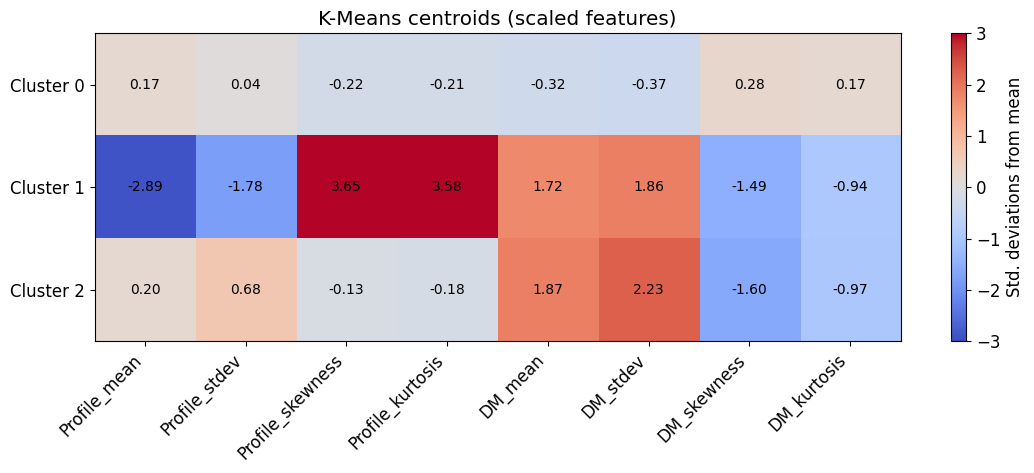

In [20]:
centers = pd.DataFrame(kmeans.cluster_centers_, columns=X.columns)

plt.figure(figsize=(13, 4))
plt.imshow(centers, cmap='coolwarm', vmin=-3, vmax=3, aspect='auto')
plt.colorbar(label="Std. deviations from mean")
plt.xticks(range(len(X.columns)), X.columns, rotation=45, ha='right')
plt.yticks(range(k_best), [f"Cluster {c}" for c in range(k_best)])

# Write the value inside each square
for i in range(k_best):
    for j in range(len(X.columns)):
        plt.text(j, i, f"{centers.iloc[i, j]:.2f}", ha='center', va='center', fontsize=10)

plt.title("K-Means centroids (scaled features)")
plt.show()

Each cluster is a different **type of signal**:

| Cluster | Integrated profile | DM-SNR curve | Interpretation |
|---|---|---|---|
| **0** (85%) | Close to average (skewness/kurtosis ≈ 0: no sharp peak) | Low `DM_mean` (3.2), very high skewness/kurtosis: one spike near DM ≈ 0 | **Typical noise and interference**, the "ordinary" candidates |
| **1** (5.5%) | Very low mean (−2.9 σ), **very high skewness (+3.7 σ) and kurtosis (+3.6 σ)**: a sharp, narrow pulse | High `DM_mean`/`DM_stdev` (+1.7 to +1.9 σ), low skewness: peaks at a non-zero DM | **Looks like a textbook pulsar** |
| **2** (9.5%) | Close to average: no sharp peak | High `DM_mean`/`DM_stdev` (+1.9 to +2.2 σ), low skewness | **DM curve looks pulsar-like, but the pulse profile doesn't**: an "in-between" group |

Cluster 2 really is different from both of the others. It matches cluster 1 on the DM curve but cluster 0 on the profile, so the third cluster is meaningful and not just an arbitrary split.

### 5.7 Visualizing the clusters on two original features
`Profile_kurtosis` (peak sharpness) against `DM_skewness` (DM-SNR peak shape), with the centroids marked by red X's (converted back to original units).

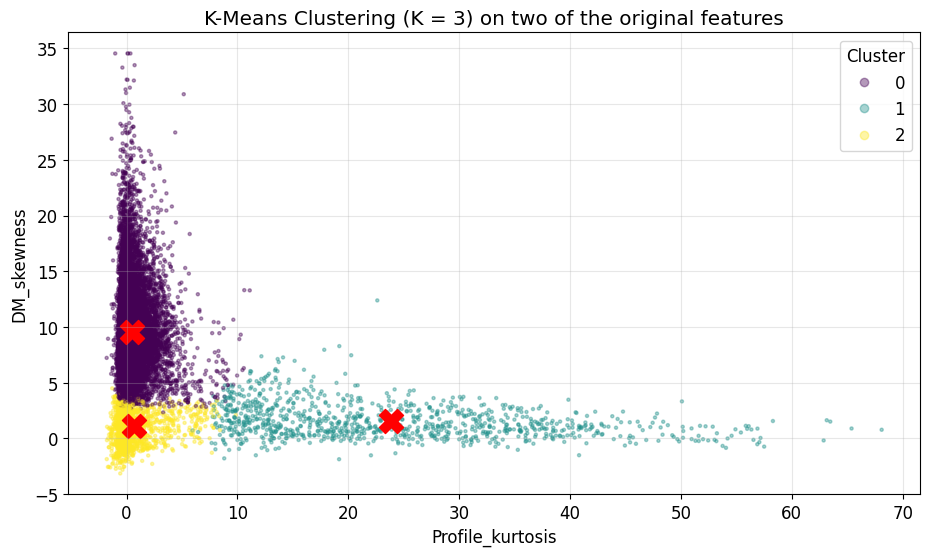

In [21]:
centers_original = scaler.inverse_transform(kmeans.cluster_centers_)
centers_original = pd.DataFrame(centers_original, columns=X.columns)

scatter = plt.scatter(X['Profile_kurtosis'], X['DM_skewness'], c=clusters, cmap="viridis", s=5, alpha=0.4)

plt.scatter(
    centers_original['Profile_kurtosis'],
    centers_original['DM_skewness'],
    c="red",
    marker="X",
    s=300
)

plt.legend(*scatter.legend_elements(), title="Cluster")
plt.xlabel("Profile_kurtosis")
plt.ylabel("DM_skewness")
plt.title(f"K-Means Clustering (K = {k_best}) on two of the original features")
plt.grid(alpha=0.3)
plt.show()

- Cluster 1 is the long "arm" from Section 3.5 (high `Profile_kurtosis`, sharp pulses).
- Clusters 0 and 2 overlap heavily at low `Profile_kurtosis` and are separated mainly by `DM_skewness`.
- Two features can't show all 8 dimensions at once, so the boundaries look messy here. This is what PCA is used for in Section 6.

### 5.8 Do the clusters mean anything? (checking against the hidden label)
K-Means never saw `class`. Comparing the two now shows whether the groups it found match something real.

In [22]:
cluster_vs_class = pd.crosstab(df['cluster'], df['class'], margins=True)
cluster_vs_class.columns = ['Not pulsar', 'Pulsar', 'Total']
cluster_vs_class['% pulsar'] = (cluster_vs_class['Pulsar'] / cluster_vs_class['Total'] * 100).round(1)
cluster_vs_class

,Not pulsar,Pulsar,Total,% pulsar
cluster,,,,
0,14852,354,15206,2.3
1,15,972,987,98.5
2,1392,313,1705,18.4
All,16259,1639,17898,9.2


- **Cluster 1 is 98.5% pulsars** (972 of 987). Without ever seeing a label, K-Means found an almost pure group of real pulsars.
- **Cluster 0 is 2.3% pulsars**: almost entirely noise.
- **Cluster 2 is mixed (18.4% pulsars)**, matching its "in-between" centroid: some weaker pulsars plus interference with a broad DM curve.
- But only **59% of all pulsars** (972 / 1,639) land in cluster 1; the rest are spread across clusters 0 and 2. The clusters capture the *clear* pulsars, not all of them.
- So the clusters are **meaningful**: they reflect real physical differences between signals, not just geometry.

## 6. Principal Component Analysis (PCA)

### 6.1 How PCA works
PCA finds new axes (**principal components**) that are linear combinations of the original features:

$$PC_j = w_{j1} z_1 + w_{j2} z_2 + \dots + w_{j8} z_8$$

- **PC1** is the direction along which the scaled data varies the most.
- **PC2** is the direction with the most remaining variance, at a right angle to (uncorrelated with) PC1. And so on.

Mathematically, the components are the **eigenvectors of the covariance matrix** of the scaled data, and each eigenvalue is the variance along its component. The **explained variance ratio** is each eigenvalue divided by the total.

PCA must be run on **scaled** data; otherwise the features with the largest units dominate the first components. Like K-Means, PCA doesn't use the label.

### 6.2 Explained variance

In [23]:
pca = PCA()   # keep all 8 components first
X_pca_all = pca.fit_transform(X_scaled)

print(pca.explained_variance_ratio_.round(3))
print(pca.explained_variance_ratio_.cumsum().round(3))

[0.517 0.268 0.101 0.057 0.032 0.02  0.003 0.002]
[0.517 0.785 0.886 0.943 0.975 0.995 0.998 1.   ]


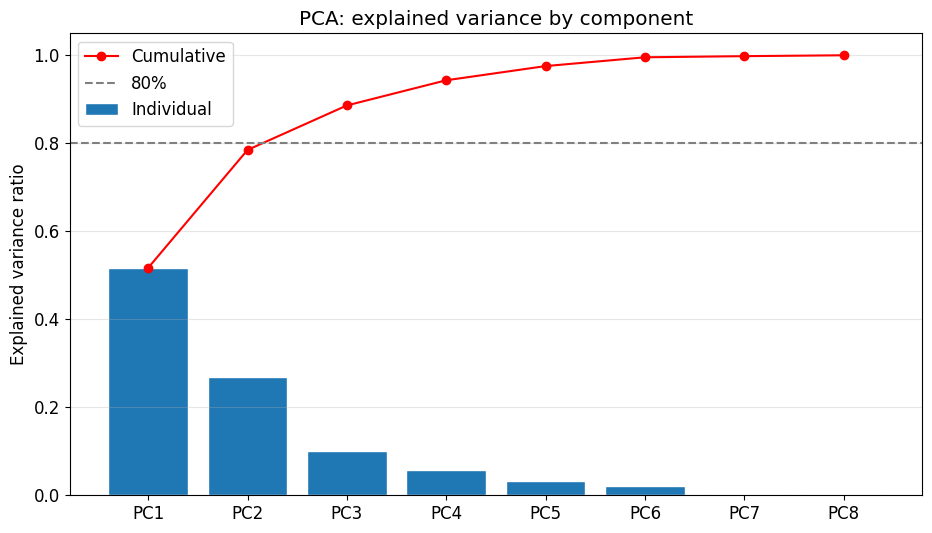

In [24]:
n_comp = len(pca.explained_variance_ratio_)
components = range(1, n_comp + 1)

plt.bar(components, pca.explained_variance_ratio_, edgecolor='white', label='Individual')
plt.plot(components, pca.explained_variance_ratio_.cumsum(), color='red', marker='o', label='Cumulative')
plt.axhline(0.80, color='gray', linestyle='--', label='80%')
plt.xticks(components, [f"PC{i}" for i in components])
plt.ylabel("Explained variance ratio")
plt.title("PCA: explained variance by component")
plt.grid(axis='y', alpha=0.3)
plt.legend()
plt.show()

In [25]:
pca2 = PCA(n_components=2)
X_pca = pca2.fit_transform(X_scaled)

print(X_pca.shape)
print(pca2.explained_variance_ratio_)
print(pca2.explained_variance_ratio_.sum())

(17898, 2)
[0.51675584 0.26807564]
0.7848314751537138


In [26]:
pca80 = PCA(n_components=0.80)
pca80.fit(X_scaled)

print("Components needed for 80% of the variance:", pca80.n_components_)
print(pca80.explained_variance_ratio_.sum())

Components needed for 80% of the variance: 3
0.8860000956209395


- **PC1 explains 51.7%** of the variance and **PC2 explains 26.8%**: together **78.5%**.
- So a 2D plot keeps about four-fifths of the information in all 8 scaled features. That's a lot, but not everything (21.5% is lost).
- 3 components are needed to pass 80% (88.6%).
- PC7 and PC8 explain almost nothing (≤ 0.3% each). This matches the strong correlations from Section 3.4: some features are almost copies of others.

### 6.3 What do PC1 and PC2 represent?
The **loadings** are the weights $w$ of each original feature in each component.

In [27]:
loadings = pd.DataFrame(pca2.components_.T, index=X.columns, columns=['PC1', 'PC2'])
loadings.round(2)

,PC1,PC2
Profile_mean,-0.36,0.36
Profile_stdev,-0.21,0.43
Profile_skewness,0.42,-0.32
Profile_kurtosis,0.40,-0.31
DM_mean,0.35,0.25
DM_stdev,0.39,0.32
DM_skewness,-0.37,-0.41
DM_kurtosis,-0.29,-0.40


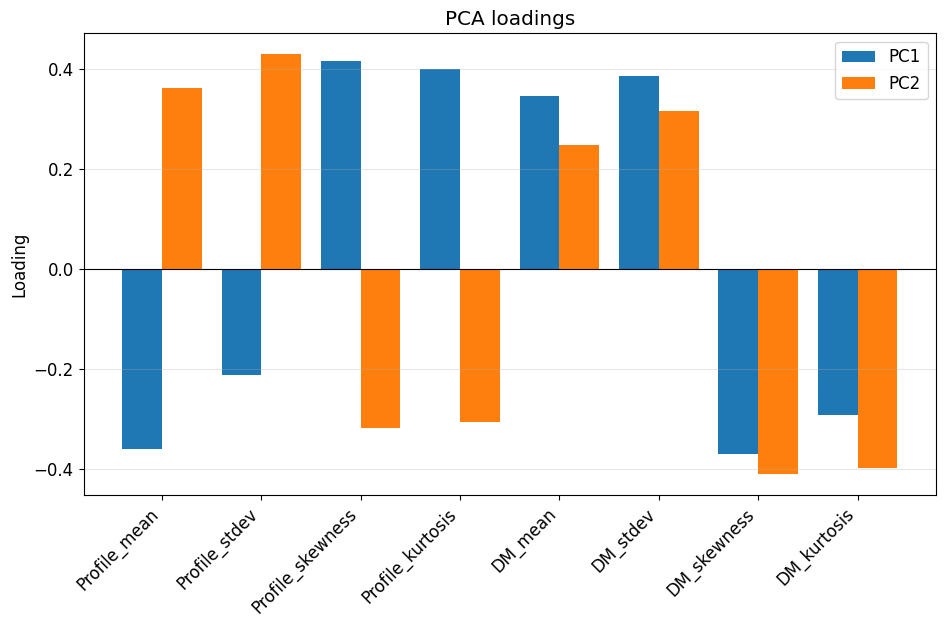

In [28]:
positions = np.arange(len(X.columns))
bar_width = 0.4

plt.bar(positions - bar_width / 2, loadings['PC1'], width=bar_width, label='PC1')
plt.bar(positions + bar_width / 2, loadings['PC2'], width=bar_width, label='PC2')
plt.axhline(0, color='black', linewidth=0.8)
plt.xticks(positions, X.columns, rotation=45, ha='right')
plt.ylabel("Loading")
plt.title("PCA loadings")
plt.grid(axis='y', alpha=0.3)
plt.legend()
plt.show()

**PC1 (51.7%) = "how pulsar-like is the signal?"**
- **Positive:** `Profile_skewness` (+0.42), `Profile_kurtosis` (+0.40), `DM_stdev` (+0.39), `DM_mean` (+0.35)
- **Negative:** `Profile_mean` (−0.36), `DM_skewness` (−0.37), `DM_kurtosis` (−0.29)
- High PC1 = a sharp, narrow pulse **and** a DM curve that peaks away from zero, exactly the pattern of cluster 1. Almost all 8 features contribute, so PC1 is a combined summary rather than one feature.

**PC2 (26.8%) = "broad vs. sharply peaked shapes"**
- **Positive:** `Profile_stdev` (+0.43), `Profile_mean` (+0.36), `DM_stdev` (+0.32), `DM_mean` (+0.25)
- **Negative:** `DM_skewness` (−0.41), `DM_kurtosis` (−0.40), `Profile_skewness` (−0.32), `Profile_kurtosis` (−0.31)
- High PC2 = wide, spread-out curves with no sharp peak, the pattern of cluster 2.

### 6.4 PCA scatter plot colored by K-Means cluster
The clusters come from Section 5 (K-Means on all 8 scaled features). PCA is used **only to draw them**; the red X's are the K-Means centroids projected onto PC1/PC2.

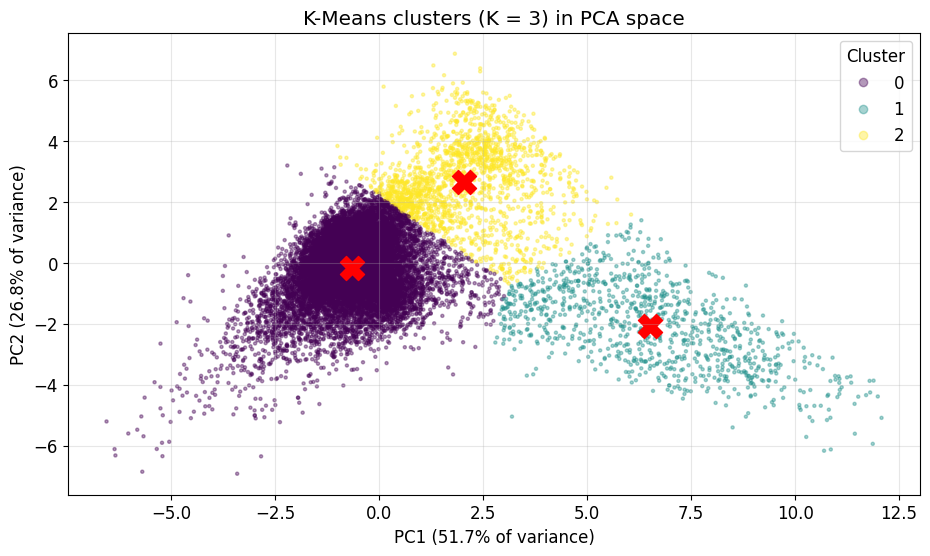

In [29]:
centers_pca = pca2.transform(kmeans.cluster_centers_)

scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=clusters, cmap="viridis", s=5, alpha=0.4)

plt.scatter(
    centers_pca[:, 0],
    centers_pca[:, 1],
    c="red",
    marker="X",
    s=300
)

plt.legend(*scatter.legend_elements(), title="Cluster")
plt.xlabel(f"PC1 ({pca2.explained_variance_ratio_[0]:.1%} of variance)")
plt.ylabel(f"PC2 ({pca2.explained_variance_ratio_[1]:.1%} of variance)")
plt.title(f"K-Means clusters (K = {k_best}) in PCA space")
plt.grid(alpha=0.3)
plt.show()

For comparison, the same PCA plot colored by the hidden `class` label:

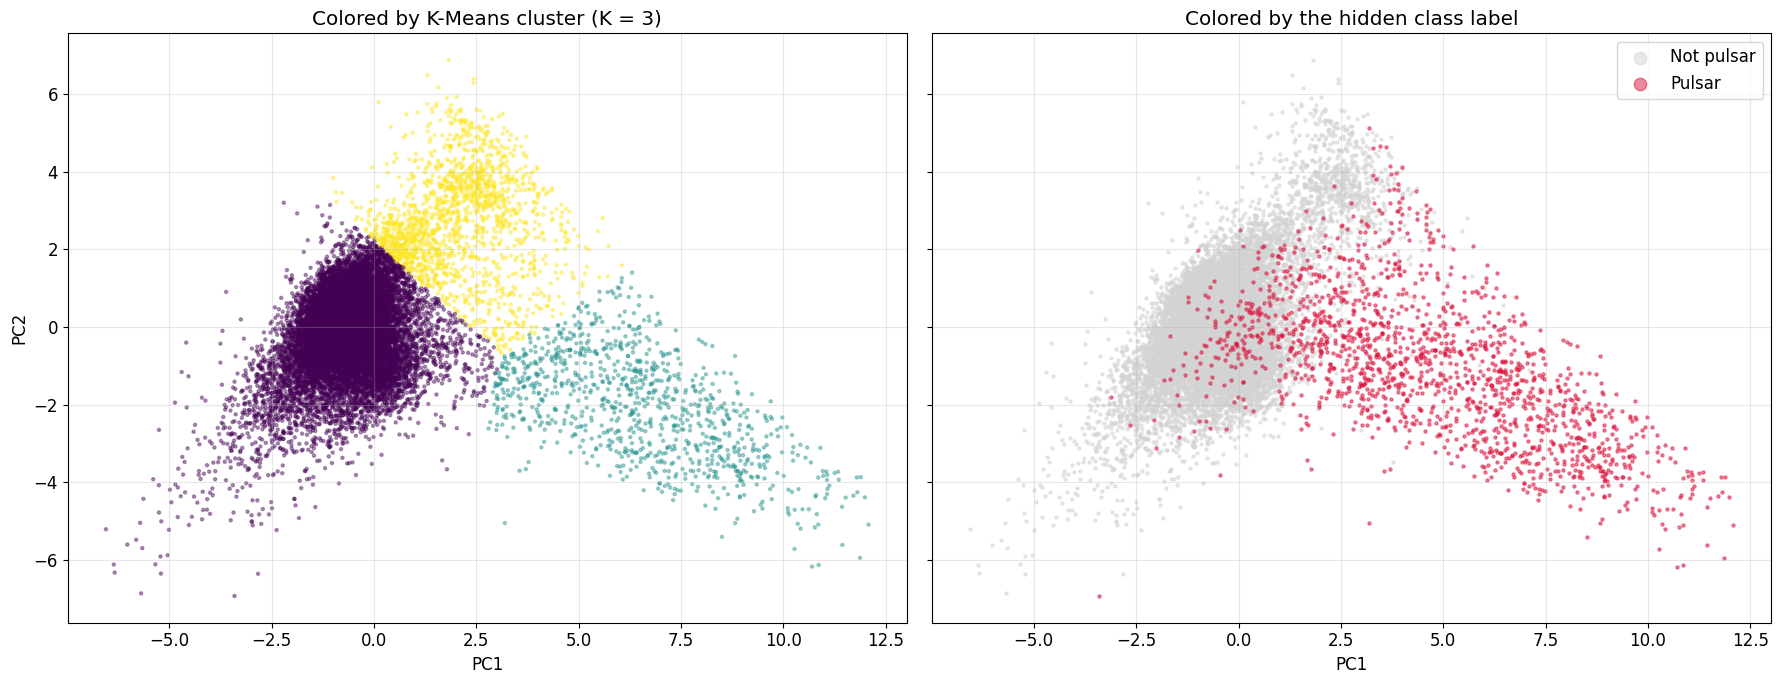

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7), sharex=True, sharey=True)

axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=clusters, cmap="viridis", s=5, alpha=0.4)
axes[0].set_title(f"Colored by K-Means cluster (K = {k_best})")

for label, color, name in [(0, 'lightgray', 'Not pulsar'), (1, 'crimson', 'Pulsar')]:
    mask = (df['class'] == label).values
    axes[1].scatter(X_pca[mask, 0], X_pca[mask, 1], c=color, s=5, alpha=0.5, label=name)
axes[1].set_title("Colored by the hidden class label")
axes[1].legend(markerscale=4)

for ax in axes:
    ax.set_xlabel("PC1")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("PC2")

plt.tight_layout()
plt.show()

### 6.5 Does PCA help visualize the clusters?
**Yes. PCA makes the clusters much easier to see** than any pair of original features (compare with Section 5.7):

- **Cluster 0** sits in the dense center-left (low PC1).
- **Cluster 1** stretches to the **bottom right** (high PC1, low PC2): the "pulsar-like" direction.
- **Cluster 2** sits at the **top** (high PC2): broad, spread-out signals.
- The centroids are far apart, and each cluster has its own region of the plot.

But the plot also shows the **limits** of the clusters:
- The data is one **continuous cloud**, not three separate blobs. The cluster boundaries are straight cuts through it, which explains why the silhouette score is good but not close to 1.
- In the right panel, the real pulsars spread along the high-PC1 side. Most are in cluster 1, but some fall into clusters 0 and 2 near the boundaries.
- The plot shows 78.5% of the variance, so some separation (or overlap) in the other 6 dimensions is hidden.

## 7. Your Investigation: K-Means on PC1 + PC2
Same procedure as Section 5, but on the 2 PCA coordinates (`X_pca`, 78.5% of the variance) instead of the 8 scaled features.

### 7.1 Choosing K again (K = 2-8)

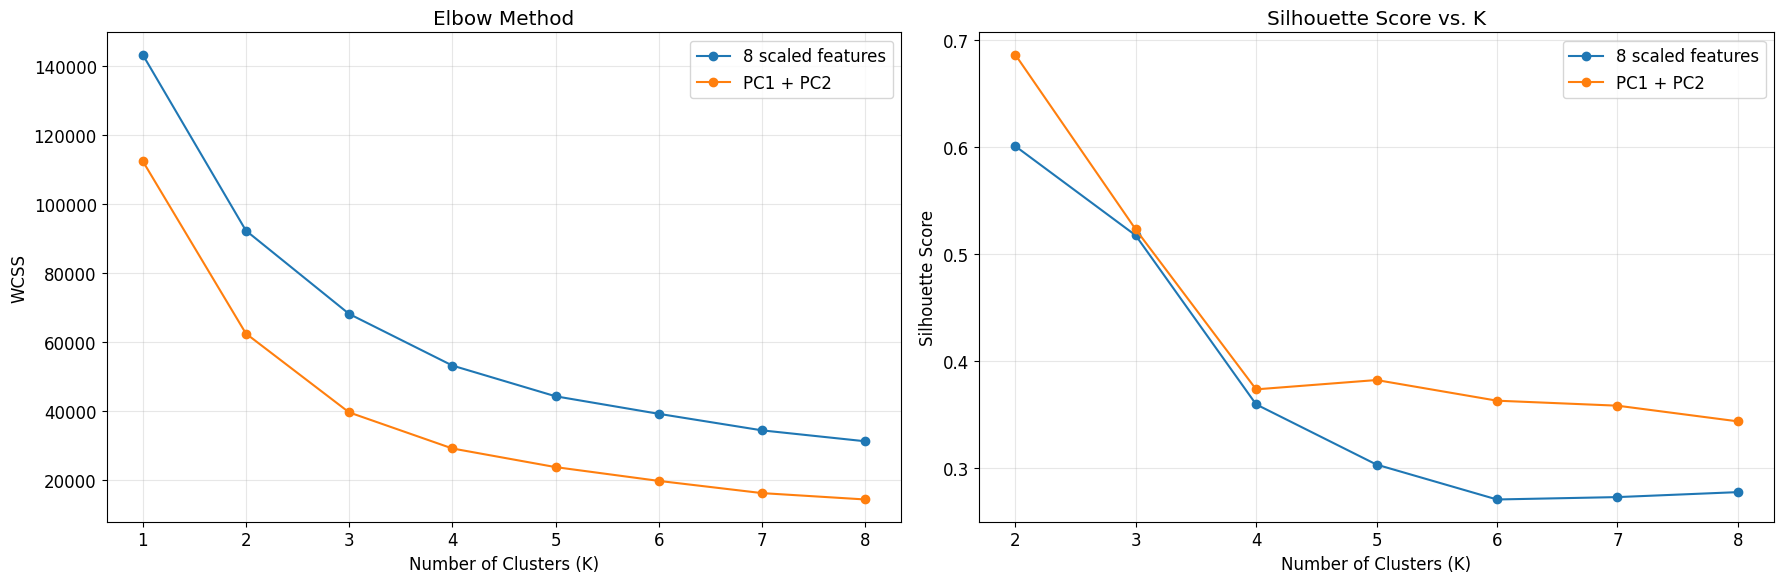

,K,"WCSS drop, PC1+PC2 (%)","Silhouette, 8 features","Silhouette, PC1+PC2"
0,2,44.5,0.601,0.687
1,3,36.6,0.518,0.523
2,4,26.4,0.360,0.374
3,5,18.5,0.303,0.382
4,6,16.9,0.271,0.363
5,7,17.9,0.273,0.358
6,8,11.4,0.278,0.344


In [31]:
wcss_pca = []
silhouette_pca = []

for k in range(1, 9):
    model = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = model.fit_predict(X_pca)
    wcss_pca.append(model.inertia_)
    if k >= 2:
        silhouette_pca.append(silhouette_score(X_pca, labels))

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

axes[0].plot(range(1, 9), wcss, marker='o', label='8 scaled features')
axes[0].plot(range(1, 9), wcss_pca, marker='o', label='PC1 + PC2')
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("WCSS")
axes[0].set_title("Elbow Method")

axes[1].plot(range(2, 9), silhouette_scores, marker='o', label='8 scaled features')
axes[1].plot(range(2, 9), silhouette_pca, marker='o', label='PC1 + PC2')
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_title("Silhouette Score vs. K")

for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

pd.DataFrame({
    'K': range(2, 9),
    'WCSS drop, PC1+PC2 (%)': (-pd.Series(wcss_pca).pct_change() * 100).round(1)[1:].values,
    'Silhouette, 8 features': np.round(silhouette_scores, 3),
    'Silhouette, PC1+PC2': np.round(silhouette_pca, 3)
})

**Decision: K = 3 again.** Same pattern as on the 8 features: silhouette is best at K = 2, still good at K = 3, then drops sharply at K = 4. The elbow bends around K = 3-4. Keeping K = 3 also makes the comparison with Section 5 direct.

(The PC1+PC2 WCSS is lower only because PCA dropped 21.5% of the variance.)

### 7.2 Final model and comparison with Section 5

In [32]:
kmeans_pca = KMeans(n_clusters=k_best, n_init=10, random_state=42)
clusters_pca = kmeans_pca.fit_predict(X_pca)

# Renumber so each PCA cluster gets the number of the Section 5 cluster it overlaps most
mapping = pd.crosstab(clusters_pca, clusters).idxmax(axis=1)
clusters_pca = mapping[clusters_pca].values
df['cluster_pca'] = clusters_pca

print("Silhouette in PC1+PC2 space:", round(silhouette_score(X_pca, clusters_pca), 3))
print("Silhouette on the 8 scaled features:", round(silhouette_score(X_scaled, clusters_pca), 3),
      "| Section 5 model:", round(silhouette_score(X_scaled, clusters), 3))
print("Adjusted Rand Index vs. Section 5:", round(adjusted_rand_score(clusters, clusters_pca), 3))
print(f"Candidates in the same cluster as Section 5: {(clusters == clusters_pca).mean():.1%}")

pd.crosstab(df['cluster'], df['cluster_pca'], rownames=['8 features'], colnames=['PC1 + PC2'])

Silhouette in PC1+PC2 space: 0.523


Silhouette on the 8 scaled features: 0.451 | Section 5 model: 0.518
Adjusted Rand Index vs. Section 5: 0.811
Candidates in the same cluster as Section 5: 95.5%


PC1 + PC2,0,1,2
8 features,,,
0,14422,4,780
1,0,985,2
2,0,15,1690


In [33]:
pca_vs_class = pd.crosstab(df['cluster_pca'], df['class'], margins=True)
pca_vs_class.columns = ['Not pulsar', 'Pulsar', 'Total']
pca_vs_class['% pulsar'] = (pca_vs_class['Pulsar'] / pca_vs_class['Total'] * 100).round(1)
pca_vs_class

,Not pulsar,Pulsar,Total,% pulsar
cluster_pca,,,,
0,14159,263,14422,1.8
1,17,987,1004,98.3
2,2083,389,2472,15.7
All,16259,1639,17898,9.2


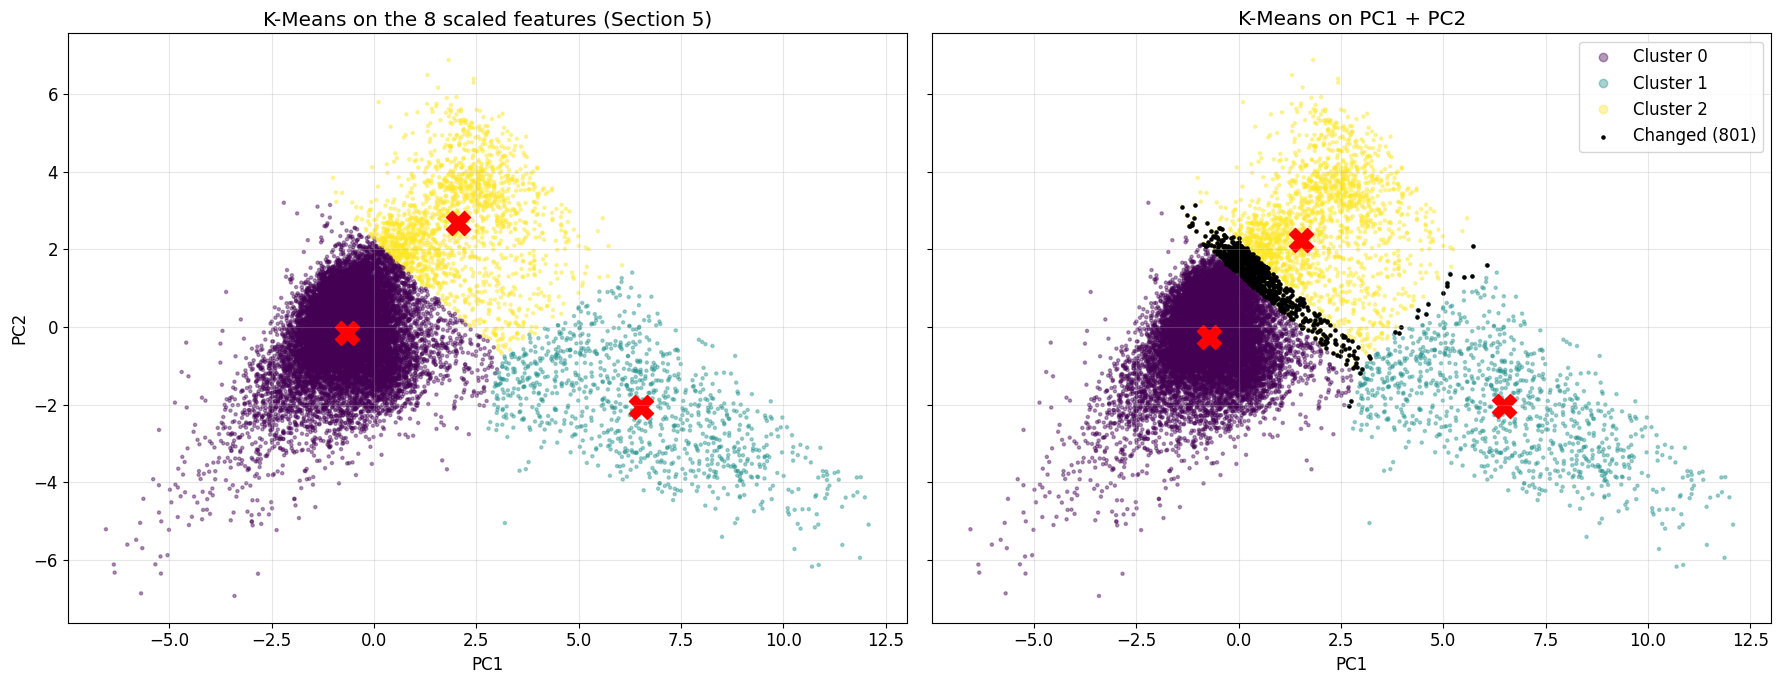

In [34]:
changed = clusters != clusters_pca
centers_pca2 = kmeans_pca.cluster_centers_

fig, axes = plt.subplots(1, 2, figsize=(18, 7), sharex=True, sharey=True)

axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=clusters, cmap='viridis', s=5, alpha=0.4)
axes[0].scatter(centers_pca[:, 0], centers_pca[:, 1], c='red', marker='X', s=300)
axes[0].set_title("K-Means on the 8 scaled features (Section 5)")

scatter = axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=clusters_pca, cmap='viridis', s=5, alpha=0.4)
axes[1].scatter(X_pca[changed, 0], X_pca[changed, 1], c='black', s=5, label=f'Changed cluster ({changed.sum()})')
axes[1].scatter(centers_pca2[:, 0], centers_pca2[:, 1], c='red', marker='X', s=300)
axes[1].set_title("K-Means on PC1 + PC2")
axes[1].legend(handles=scatter.legend_elements()[0] + [axes[1].collections[1]],
               labels=['Cluster 0', 'Cluster 1', 'Cluster 2', f'Changed ({changed.sum()})'])

for ax in axes:
    ax.set_xlabel("PC1")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("PC2")

plt.tight_layout()
plt.show()

- **95.5%** of candidates keep their cluster (ARI 0.81).
- **The pulsar cluster (1) barely changes:** 985 of its 987 candidates stay, and it is still 98.3% pulsars.
- **The change is at the border between clusters 0 and 2:** 780 noise candidates move into cluster 2, which grows from 1,705 to 2,472 and drops from 18.4% to 15.7% pulsars.
- On the 8 features the PC-based clusters fit worse (silhouette 0.451 vs. 0.518). The 21.5% of variance PCA dropped holds part of what separates clusters 0 and 2.

## 8. Conclusions

**Did PCA make the clusters easier to visualize?**
Yes. On two raw features (5.7) clusters 0 and 2 overlap. On PC1/PC2 (6.4) each cluster has its own region: pulsars out along PC1, broad signals up along PC2. Two axes keep 78.5% of the variance.

**Did reducing the number of features change the clustering results?**
Only a little. The pulsar cluster is almost identical, and 95.5% of candidates keep their cluster. What changes is the noise vs. "in-between" border, which depends on the 21.5% of variance PCA dropped.

**What did the Elbow Method and Silhouette Score tell you?**
The elbow only bends gradually (K = 3-4), so on its own it doesn't settle K. The silhouette is clearer: best at K = 2, still good at K = 3, then a sharp drop at K = 4. Both spaces give the same picture. Beyond K = 3 K-Means just cuts the main cloud into arbitrary pieces.

**What is the most interesting pattern you discovered?**
Without ever seeing a label, K-Means found a group of 987 candidates that is **98.5% real pulsars**, defined by a sharp, narrow pulse plus a DM curve peaking away from zero. PC1 alone works as a "how pulsar-like" axis.

**What are the limitations of your analysis?**
- K-Means assumes round clusters of similar spread. Here the data is one continuous, skewed cloud with very unequal groups, so the boundaries are straight cuts through it.
- The long-tailed features still pull the centroids after scaling (no log transform was tried).
- Only 59% of the pulsars land in the pulsar cluster. The clusters find the clear pulsars, not the faint ones, so this doesn't replace a classifier.
- PCA is linear, and a 2D picture hides 21.5% of the variance.